# 04 Test: the models on the test period, once

**Purpose:** Evaluate the final model, chosen on the backtest only (`03_evaluate.ipynb`, section 10), on the test period (2024-10 to 2026-09), together with the simple rules and every other candidate of both model families, all in one table. This is the only notebook that uses the test period.
**Input:** `../data/processed/asylum_clean.csv`, `routes_clean.csv`, `neighbours_clean.csv`, and `../output/tables/03_backtest_errors.csv` and `03_two_models.csv` (from `03_evaluate.ipynb`).
**Output:** `../data/processed/test_forecasts.csv`, `../output/tables/04_test_errors.csv` and `../output/figures/04_test_forecasts_h2.png`.

**The choice was made before the test** (notebook 209, Step 7): the linear regression on the series' own past. The other models are shown next to it so that the whole comparison is visible; we do not change the choice after seeing the results below (notebook 209, Step 8).

**Timeline.** The group fixed the choice rule and chose the linear regression on 17 November 2026 (commit `c6a3976`), then ran the test once (commit `4f284f5`). The random walk, the neighbouring countries, the lag test (`02d`) and the one-year horizon (`02e`) were added afterwards, on the backtest only. The rule was not changed, and it still chooses the linear regression (`03`, section 10), so the test result of the chosen model is the same as in the first run.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso

np.random.seed(42)
plt.style.use("seaborn-v0_8-muted")

## 1. Load the whole series

For the first time, we use all 225 months, including the 24 months of the test period.

In [2]:
clean = pd.read_csv("../data/processed/asylum_clean.csv")
clean["month"] = pd.to_datetime(clean["month"])
clean = clean.set_index("month")

y = clean["applicants_total"].to_numpy(dtype=float)
log_y = clean["log_applicants"].to_numpy(dtype=float)
months = clean.index

last_backtest = int(np.where(months == pd.Timestamp("2024-09-01"))[0][0])
last_month = len(months) - 1
H_MAX = 3

print(clean["period"].value_counts())
print("Last backtest month:", months[last_backtest], "| last month:", months[last_month])

def load(path):
    data = pd.read_csv(path)
    data["month"] = pd.to_datetime(data["month"])
    return data.set_index("month")

log_routes = load("../data/processed/routes_clean.csv")["log_routes"].reindex(months).to_numpy(dtype=float)
log_neighbours = load("../data/processed/neighbours_clean.csv")["log_neighbours"].reindex(months).to_numpy(dtype=float)

period
backtest    141
training     60
test         24
Name: count, dtype: int64
Last backtest month: 2024-09-01 00:00:00 | last month: 2026-09-01 00:00:00


## 2. The models, exactly as in the backtest

- **Simple rules** (`02_estimate.ipynb`): the 12-month average (the best simple baseline of our plan) and the random walk (the last known month).
- **Family 1** (`02b`): linear regression (our chosen model), Ridge and Lasso on the series' own past.
- **Family 2** (`02c`): the same three regressions with the routes, with the neighbouring countries and with both.

The functions are copied from `02`, `02b` and `02c` without any change; first we check that the copy gives exactly the stored backtest forecasts at the last backtest origin.

In [3]:
features = {   # copied from 02c
    "routes": {"routes_change_last_month": lambda t: log_routes[t - 1] - log_routes[t - 2],
               "routes_change_3_months": lambda t: log_routes[t - 1] - log_routes[t - 4]},
    "neighbours": {"neighbours_change_last_month": lambda t: log_neighbours[t - 1] - log_neighbours[t - 2],
                   "neighbours_change_3_months": lambda t: log_neighbours[t - 1] - log_neighbours[t - 4]},
}
combinations = {"": [], " + routes": ["routes"], " + neighbours": ["neighbours"],
                " + all indicators": ["routes", "neighbours"]}

def make_table(h, parts):
    # Copied from 02c; with no indicator it is the table of 02b
    extra_features = {k: f for b in parts for k, f in features[b].items()}
    rows = []
    for t in range(12, len(log_y) - h):
        values = {name: f(t) for name, f in extra_features.items()}
        if any(np.isnan(v) for v in values.values()):
            continue
        rows.append({"t": t,
                     "change_last_month": log_y[t] - log_y[t - 1],
                     "change_month_before": log_y[t - 1] - log_y[t - 2],
                     "same_change_last_year": log_y[t + h - 12] - log_y[t - 12],
                     **values,
                     "calendar_month": months[t + h].month,
                     "target": log_y[t + h] - log_y[t]})
    table = pd.DataFrame(rows).set_index("t")
    dummies = pd.get_dummies(table["calendar_month"], prefix="month", drop_first=True).astype(float)
    names = ["change_last_month", "change_month_before", "same_change_last_year"] + list(extra_features)
    return pd.concat([table[names], dummies], axis=1), table["target"]

def make_model(name, alpha=None):
    # Copied from 02b
    if name == "Linear regression":
        return make_pipeline(StandardScaler(), LinearRegression())
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    return make_pipeline(StandardScaler(), Lasso(alpha=alpha, max_iter=10000))

alpha_grids = {"Linear regression": [None], "Ridge": [0.1, 1, 10, 100, 1000, 10000],
               "Lasso": [0.0001, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3]}

def choose_alpha(name, X, target, T, h, n_blocks=2, block=12):
    # Copied from 02b
    grid = alpha_grids[name]
    if len(grid) == 1:
        return grid[0]
    first_row, last_row = X.index.min(), T - h
    scores = []
    for alpha in grid:
        mse_blocks = []
        for b in range(n_blocks):
            start = last_row - n_blocks * block + 1 + b * block
            valid_rows = list(range(start, start + block))
            train_rows = list(range(first_row, start - h + 1))
            model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
            errors = target.loc[valid_rows].to_numpy() - model.predict(X.loc[valid_rows])
            mse_blocks.append(np.mean(errors ** 2))
        scores.append(np.mean(mse_blocks))
    return grid[int(np.argmin(scores))]

def average_12(train_y, h_max):
    # Copied from 02: average of the last 12 known months, the same for every horizon
    return np.log(np.full(h_max, train_y[-12:].mean()))

tables = {(suffix, h): make_table(h, parts) for suffix, parts in combinations.items() for h in range(1, H_MAX + 1)}

def regression_forecast(name, suffix, t, h):
    # one forecast of log applications at origin t, refitted on the months known at t
    X, target = tables[(suffix, h)]
    train_rows = list(range(X.index.min(), t - h + 1))
    assert max(train_rows) + h <= t                       # no training target after the origin
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        alpha = choose_alpha(name, X, target, t, h)
        model = make_model(name, alpha).fit(X.loc[train_rows], target.loc[train_rows])
    return log_y[t] + model.predict(X.loc[[t]])[0]

# Check the copy at the last backtest origin (2024-08, h = 1)
stored = pd.concat([pd.read_csv("../data/processed/backtest_forecasts_regression.csv"),
                    pd.read_csv("../data/processed/backtest_forecasts_indicator.csv")])
for name in alpha_grids:
    for suffix in combinations:
        s = stored[(stored["model"] == name + suffix) & (stored["origin"] == str(months[last_backtest - 1].date())) & (stored["h"] == 1)]
        assert np.isclose(regression_forecast(name, suffix, last_backtest - 1, 1), s["forecast_log"].iloc[0]), name + suffix
print("The copied functions reproduce the stored backtest forecasts of all 12 regressions.")

The copied functions reproduce the stored backtest forecasts of all 12 regressions.


## 3. Forecasts for the test period

We continue the backtest into the test period with the same rule: at each origin, the models are fitted on **all months known at that origin and nothing after it**, and we forecast $h = 1, 2, 3$. The origins go from September 2024 (the last backtest month) to August 2026. So the forecasts for, say, March 2026 are made with the months up to December 2025 ($h = 3$), January 2026 ($h = 2$) or February 2026 ($h = 1$), as a planner would have had them.

This is the time-series version of "refit on all training data, then test" (notebook 209, Step 8): there is no single refit, because in practice the model is refitted every month when a new number arrives. We expect 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$ per model.

In [4]:
rows = []
for t in range(last_backtest, last_month):          # origins 2024-09 to 2026-08
    for h in range(1, H_MAX + 1):
        target_pos = t + h
        if target_pos > last_month:
            continue
        logs = {"12-month average": average_12(y[: t + 1], H_MAX)[h - 1], "Random walk": log_y[t]}
        for name in alpha_grids:
            for suffix in combinations:
                logs[name + suffix] = regression_forecast(name, suffix, t, h)
        for name, forecast_log in logs.items():
            rows.append({"model": name, "origin": months[t], "month": months[target_pos], "h": h,
                         "forecast_log": forecast_log, "actual_log": log_y[target_pos],
                         "forecast": np.exp(forecast_log), "actual": y[target_pos]})

test_forecasts = pd.DataFrame(rows)
print(test_forecasts.groupby("h").size() / test_forecasts["model"].nunique(), "forecasts per model and horizon;",
      test_forecasts["model"].nunique(), "models")
print("All forecast months in the test period:", (test_forecasts["month"] >= pd.Timestamp("2024-10-01")).all())
print("All forecast months after their origin:", (test_forecasts["month"] > test_forecasts["origin"]).all())
print("Missing or infinite forecasts:", (~np.isfinite(test_forecasts["forecast_log"])).sum())

h
1    24.0
2    23.0
3    22.0
dtype: float64 forecasts per model and horizon; 14 models
All forecast months in the test period: True
All forecast months after their origin: True
Missing or infinite forecasts: 0


**What we see.** Each model has 24 forecasts for $h = 1$, 23 for $h = 2$ and 22 for $h = 3$, as expected. All forecast months lie in the test period and after their origin, and no forecast is missing. Together with the `assert` in the loop, this shows that each forecast used only the months known at its origin.

## 4. Test errors

The same two error measures as in `03_evaluate.ipynb`: the MAE in persons (main) and the RMSE in logs.

In [5]:
test_forecasts["abs_error"] = (test_forecasts["actual"] - test_forecasts["forecast"]).abs()
test_forecasts["sq_error_log"] = (test_forecasts["actual_log"] - test_forecasts["forecast_log"]) ** 2

grouped = test_forecasts.groupby(["model", "h"])
test_errors = pd.DataFrame({
    "MAE (persons)": grouped["abs_error"].mean(),
    "MSE (log)": grouped["sq_error_log"].mean(),
    "RMSE (log)": np.sqrt(grouped["sq_error_log"].mean()),
    "forecasts": grouped["abs_error"].size(),
}).reset_index()
test_errors.to_csv("../output/tables/04_test_errors.csv", index=False)

order = ["12-month average", "Random walk"] + [n + s for s in combinations for n in alpha_grids]
table = test_errors.pivot(index="model", columns="h", values="MAE (persons)").loc[order].round(0)
table.columns = [f"MAE h={h}" for h in table.columns]
table["MSE log h=2"] = test_errors[test_errors["h"] == 2].set_index("model").loc[order, "MSE (log)"].round(4)
table

,MAE h=1,MAE h=2,MAE h=3,MSE log h=2
model,,,,
12-month average,297.0,331.0,359.0,0.0365
Random walk,187.0,269.0,358.0,0.0258
Linear regression,149.0,188.0,217.0,0.0126
Ridge,130.0,192.0,222.0,0.0131
Lasso,152.0,192.0,217.0,0.0144
Linear regression + routes,151.0,197.0,227.0,0.0125
Ridge + routes,128.0,193.0,218.0,0.0131
Lasso + routes,150.0,193.0,224.0,0.0126
Linear regression + neighbours,154.0,194.0,228.0,0.0128


**What we see.** At $h = 2$, the chosen linear regression misses by 188 applications per month, the 12-month average by 331 and the random walk by 269. The other regressions of both families lie between 182 and 213: the lowest are Ridge with both indicators (182) and Ridge with the neighbours (186), then Ridge and Lasso on the own past (192). At $h = 1$, Ridge with the neighbours is lowest (121).

### The main comparison at $h = 2$

In [6]:
h2 = test_errors[test_errors["h"] == 2].set_index("model")
model_2 = pd.read_csv("../output/tables/03_two_models.csv").set_index("family").loc["all indicators", "model"]
mae_lr = h2.loc["Linear regression", "MAE (persons)"]
for other in ["12-month average", "Random walk", model_2]:
    mae_o = h2.loc[other, "MAE (persons)"]
    print(f"Linear regression {mae_lr:.1f} against {other} {mae_o:.1f}: {100 * (1 - mae_lr / mae_o):.0f}% lower MAE, "
          f"{100 * (1 - h2.loc['Linear regression', 'RMSE (log)'] / h2.loc[other, 'RMSE (log)']):.0f}% lower RMSE (log)")
print("Success rule of our plan (at least 10% lower MAE than the best simple baseline):",
      mae_lr <= 0.9 * h2.loc["12-month average", "MAE (persons)"])
print(f"For comparison, average actual number of applications in these months: {test_forecasts[test_forecasts['h'] == 2]['actual'].mean():.0f}")

Linear regression 188.0 against 12-month average 331.3: 43% lower MAE, 41% lower RMSE (log)
Linear regression 188.0 against Random walk 269.1: 30% lower MAE, 30% lower RMSE (log)
Linear regression 188.0 against Ridge + all indicators 182.0: -3% lower MAE, -1% lower RMSE (log)
Success rule of our plan (at least 10% lower MAE than the best simple baseline): True
For comparison, average actual number of applications in these months: 1982


**What we see.**
- At $h = 2$, the linear regression misses by **188 applications per month** on average, against 331 for the 12-month average: **43% lower MAE** and 41% lower RMSE (log). Our success rule (at least 10% better than the best simple baseline) is met.
- Against the random walk (269) it is 30% better, much more than in the backtest (5%).
- Model 2, Ridge with both indicators, misses by 182, 3% less than the linear regression (RMSE (log) 1% lower). With 23 forecasts, a gap of 6 applications per month is far within the noise, and in the backtest model 2 was 1.9% worse. We keep our choice.
- In these months there were on average 1,982 applications per month, so the chosen model misses by about a tenth of a typical month.

## 5. Test against backtest

How do the test errors compare with the backtest errors of the same models (from `03_evaluate.ipynb`)? The backtest error of the chosen model is a little too optimistic, because it won the comparison (notebook 108b). The two periods also differ in how hard they are: we put the average number of applications next to the errors.

In [7]:
backtest = pd.read_csv("../output/tables/03_backtest_errors.csv").set_index("model")
comparison = pd.DataFrame(index=list(dict.fromkeys(["Linear regression", "12-month average", "Random walk", model_2])))
for h in [1, 2, 3]:
    comparison[f"backtest MAE h={h}"] = backtest.loc[comparison.index, f"MAE h={h}"]
    comparison[f"test MAE h={h}"] = [test_errors[(test_errors["model"] == m) & (test_errors["h"] == h)]["MAE (persons)"].iloc[0]
                                     for m in comparison.index]
print(comparison.round(0))
print()
level = clean.groupby("period")["applicants_total"].agg(["mean", "std"]).round(0)
print("Applications per month in each period:")
print(level)

                        backtest MAE h=1  test MAE h=1  backtest MAE h=2  \
Linear regression                  256.0         149.0             358.0   
12-month average                   487.0         297.0             528.0   
Random walk                        259.0         187.0             379.0   
Ridge + all indicators             247.0         128.0             365.0   

                        test MAE h=2  backtest MAE h=3  test MAE h=3  
Linear regression              188.0             452.0         217.0  
12-month average               331.0             558.0         359.0  
Random walk                    269.0             487.0         358.0  
Ridge + all indicators         182.0             476.0         213.0  

Applications per month in each period:
            mean    std
period                 
backtest  1852.0  888.0
test      2008.0  338.0
training  1678.0  561.0


**What we see.**
- All models have **much smaller errors in the test period** than in the backtest: the linear regression 188 instead of 358 at $h = 2$, the 12-month average 331 instead of 528.
- The test period is much calmer: the standard deviation of the monthly applications is 338, against 888 in the backtest, for a similar average (2,008 against 1,852).
- The random walk gains less (379 to 269) than the regressions, because the test period has a clear seasonal pattern, which the random walk ignores.

**What this means for us.** The smaller test errors come mostly from an **easier period**, not from a model that got better: the simple rule improves just as much. This is why we compare the models on the same months, and not the test error with the backtest error. With only 23 forecasts at $h = 2$, the test MAE is also uncertain; in a new crisis like 2015-16, the errors would be much larger (`03_evaluate.ipynb`, section 5).

## 6. The forecasts two months ahead, month by month

The table shows what a planner would have seen: for each month of the test period, the forecast made two months earlier and the actual number.

In [8]:
h2_forecasts = test_forecasts[test_forecasts["h"] == 2]
monthly = h2_forecasts.pivot(index="month", columns="model", values="forecast")[["12-month average", "Linear regression", model_2]].round(0)
monthly.insert(0, "Actual", h2_forecasts.groupby("month")["actual"].first())
monthly["error of the linear regression"] = monthly["Linear regression"] - monthly["Actual"]
monthly

model,Actual,12-month average,Linear regression,Ridge + all indicators,error of the linear regression
month,,,,,
2024-11-01,2320.0,2485.0,2480.0,2582.0,160.0
2024-12-01,1850.0,2409.0,2179.0,2209.0,329.0
2025-01-01,1910.0,2341.0,2118.0,2198.0,208.0
2025-02-01,1765.0,2308.0,1702.0,1727.0,-63.0
2025-03-01,1825.0,2237.0,1642.0,1740.0,-183.0
2025-04-01,1890.0,2180.0,1573.0,1660.0,-317.0
2025-05-01,2020.0,2134.0,1723.0,1808.0,-297.0
2025-06-01,2210.0,2102.0,2270.0,2133.0,60.0
2025-07-01,2480.0,2074.0,2441.0,2400.0,-39.0


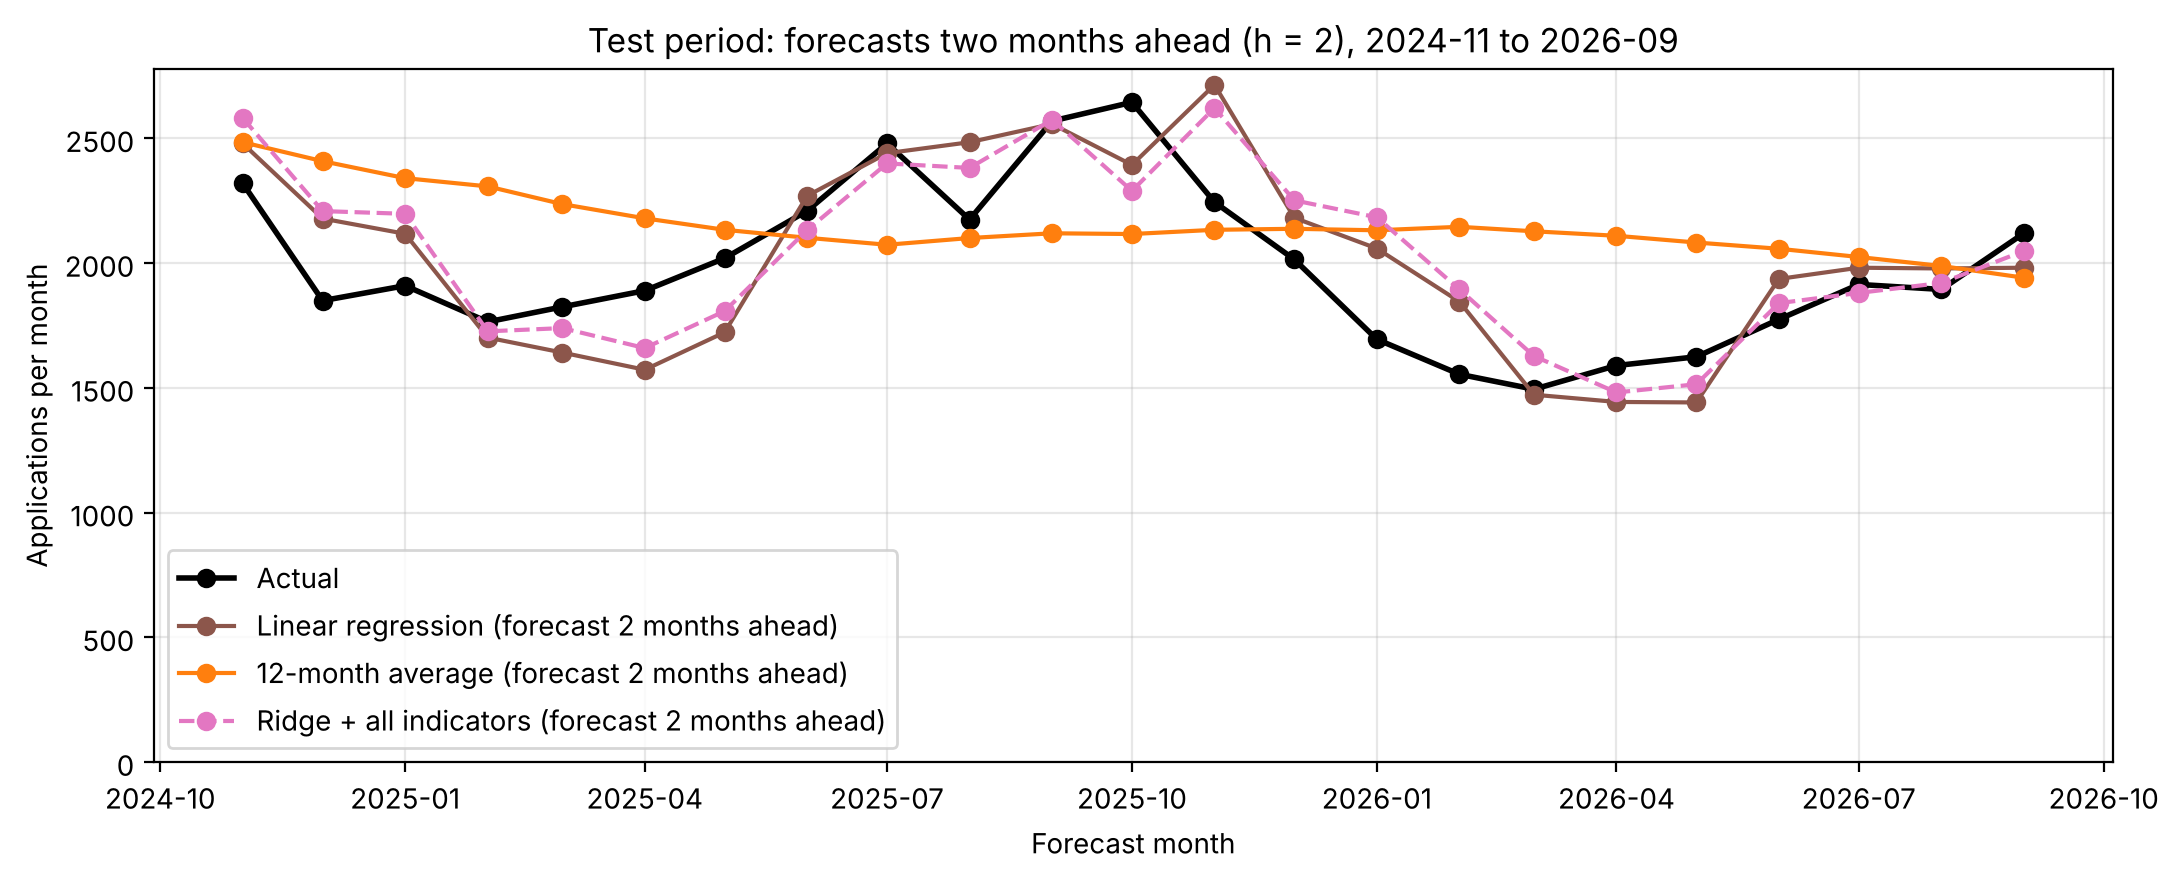

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(monthly.index, monthly["Actual"], color="black", linewidth=2, marker="o", label="Actual")
ax.plot(monthly.index, monthly["Linear regression"], color=plt.cm.tab10(5), marker="o", label="Linear regression (forecast 2 months ahead)")
ax.plot(monthly.index, monthly["12-month average"], color=plt.cm.tab10(1), marker="o", label="12-month average (forecast 2 months ahead)")
ax.plot(monthly.index, monthly[model_2], color=plt.cm.tab10(6), marker="o", linestyle="--", label=f"{model_2} (forecast 2 months ahead)")
ax.set_title("Test period: forecasts two months ahead (h = 2), 2024-11 to 2026-09")
ax.set_xlabel("Forecast month")
ax.set_ylabel("Applications per month")
ax.set_ylim(bottom=0)
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../output/figures/04_test_forecasts_h2.png")
plt.show()

**What we see.**
- The 12-month average is almost a flat line around 2,000 to 2,500: it cannot follow the rise in summer and autumn 2025 or the fall in early 2026.
- The linear regression follows the seasonal pattern (the rise from June to October 2025 and again from June 2026). In 14 of the 23 months, it misses by 200 or less.
- Ridge with both indicators (dashed) follows almost the same path: the two forecasts differ by 80 applications on average, at most 155.
- The largest errors come right **after turning points**: too low in March to May 2025 (−183 to −317), too high in November 2025 to February 2026 (+470 in November).

**What this means for us.** The models react to the newest changes, but only once they are visible in the data. A planner can use the forecast as a monthly guide, but should expect misses of a few hundred applications at turning points.

## 7. Which data help on the test months?

As in `03_evaluate.ipynb` (section 7): each regression against its own versions with indicators, on the test months, by MAE and MSE (log). Information only: the choice is fixed.

In [10]:
rows = []
for name in alpha_grids:
    for suffix in [" + routes", " + neighbours", " + all indicators"]:
        for h in [1, 2, 3]:
            a_ = test_errors[(test_errors["model"] == name + suffix) & (test_errors["h"] == h)].iloc[0]
            b_ = test_errors[(test_errors["model"] == name) & (test_errors["h"] == h)].iloc[0]
            rows.append({"indicators": suffix[3:], "model": name, "h": h,
                         "change in MAE (%)": 100 * (a_["MAE (persons)"] / b_["MAE (persons)"] - 1),
                         "change in MSE log (%)": 100 * (a_["MSE (log)"] / b_["MSE (log)"] - 1)})
pd.DataFrame(rows).pivot_table(index=["indicators", "model"], columns="h",
                               values=["change in MAE (%)", "change in MSE log (%)"], sort=False).round(1)

change in MAE (%)             \
h                                                1     2    3   
indicators     model                                            
routes         Linear regression               1.2   4.9  4.3   
               Ridge                          -0.9   0.2 -1.8   
               Lasso                          -1.3   0.5  3.2   
neighbours     Linear regression               2.9   3.0  5.0   
               Ridge                          -6.4  -3.3  0.9   
               Lasso                          -5.0  10.7  4.6   
all indicators Linear regression               3.9   4.3  5.5   
               Ridge                          -1.4  -5.4 -4.1   
               Lasso                           2.4   6.3  4.1   

                                 change in MSE log (%)              
h                                                    1     2     3  
indicators     model                                                
routes         Linear regression                  -1.7  -0.9   3.5  
               Ridge                               1.1  -0.7  -3.2  
               Lasso                               0.6 -12.8   2.5  
neighbours     Linear regression                  -0.9   1.0   4.2  
               Ridge                              -1.7  -0.4  -1.9  
               Lasso                              -0.1  10.8   9.1  
all indicators Linear regression                   2.1  -1.3   6.0  
               Ridge                               0.8  -5.6  -6.3  
               Lasso                               6.6   5.4  11.1

**What we see.** On the test months the picture is mixed. With both indicators, Ridge is 5.4% better at $h = 2$ and 4.1% at $h = 3$, but the linear regression and Lasso are worse (+4.3% and +6.3% at $h = 2$). The routes change little (−1.8% to +4.9% MAE); the neighbours help Ridge at $h = 1$ and $h = 2$ (−6.4% and −3.3%) and hurt Lasso (+10.7% at $h = 2$).

**What this means for us.** Small effects that change sign from one model to the next: as in the backtest, no indicator gives a clear, consistent gain. This supports our choice; we did not change it because of these numbers.

## 8. Save the test forecasts

In [11]:
test_forecasts.drop(columns=["abs_error", "sq_error_log"]).to_csv("../data/processed/test_forecasts.csv", index=False)
print("Saved", test_forecasts.shape[0], "test forecasts")

Saved 966 test forecasts


## Summary

- **Choice (made before this notebook, `03_evaluate.ipynb` section 10):** the linear regression on the series' own past.
- **Test result at $h = 2$:** MAE 188 applications per month against 331 for the 12-month average, **43% lower**; RMSE (log) 41% lower. The success rule of our plan is met, and the ranking holds at $h = 1$ and $h = 3$ (149 against 297, 217 against 359). Against the random walk (269): 30% lower.
- **The other candidates:** the regressions of both families lie between 182 and 213 at $h = 2$; Ridge with both indicators (182) is 3% below the chosen model, within the noise (it was 1.9% worse in the backtest). The indicators give no consistent gain.
- **Careful reading:** the test period (2024-10 to 2026-09) was calm, so all models have smaller errors than in the backtest; only 23 forecasts at $h = 2$; the largest misses come after turning points.
- **The test period was used for one decision only.** The choice was not changed after seeing these results.